# Librerias y constantes

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class

AS = 2.1E-9
H = 0.7
H0 = 100 * H  # km/s/Mpc

OMATERIA = 0.3
ZEQ = 1300

KEQ = np.sqrt(2 * OMATERIA * H0**2 * (1 + ZEQ)) # km/s/Mpc
ALPHA = (2 / 5 / OMATERIA / 100**2)*2 # (Mpc*s/km)^4


# Item $(a)$

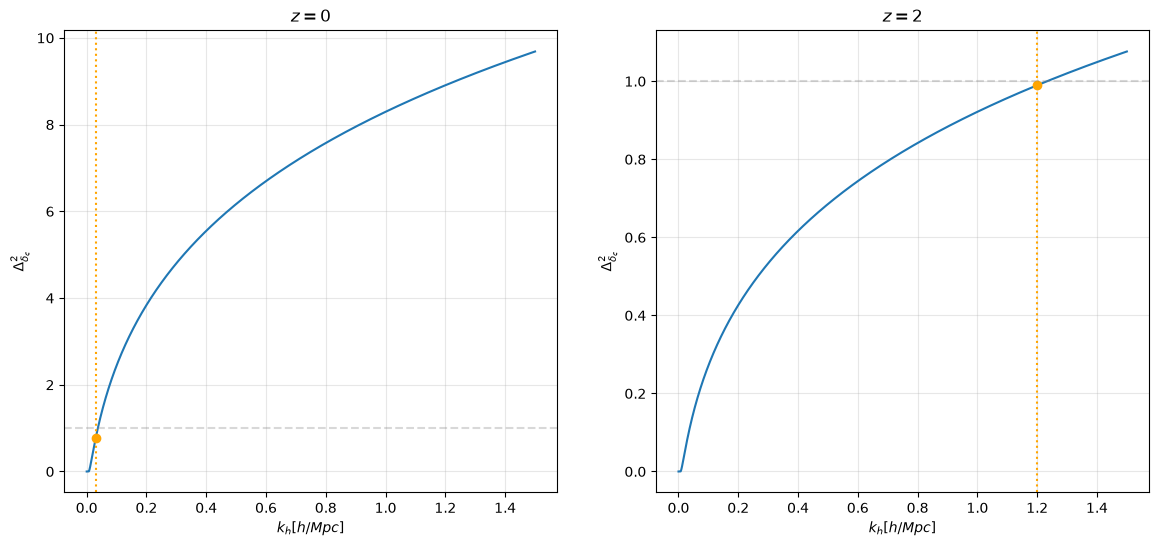

In [156]:
def T(k_array, keq = KEQ):
    result = []
    for k in k_array:
        if k < keq:
            result.append(1)
        else:
            result.append(12*np.log(k/keq)*(keq/k)**2)

    return np.array(result)

var = lambda k, z: ALPHA * T(k)**2 * AS * (k/H)**4 / (1 + z)**2

k = np.logspace(-4, np.log10(1.5), 10_000)

# Puntos de interseccion (post ver grafico)
khnls = {
    '0': .03,
    '2': 1.2,
}

# Figura
fig, ax = plt.subplots(1, 2, figsize = (14, 6), sharex = True)

for (i, z) in enumerate([0, 2]):
    ax[i].plot(k, var(k, z))
    ax[i].plot(khnls[f'{z}'], var(np.array([khnls[f'{z}']]), z), 
               marker='o', color='orange')

    ax[i].axhline(1, linestyle = '--', color = 'gray', alpha = .3)
    ax[i].axvline(khnls[f'{z}'], linestyle = ':', color = 'orange')

    ax[i].set(xlabel = r'$k_h [h/Mpc]$', 
              ylabel = r'$\Delta^2_{\delta_c}$', 
              title = r'$z = $' + f'{z}')
    ax[i].grid(alpha = .3)

fig.savefig('knls.png', bbox_inches = 'tight')
plt.show()

# Item $(b)$

Como es la primera vez que voy a utilizar el código solo voy a hacer notaciones para irme guiando en lo que estoy haciendo.

Primero, paso los parámetros que aparecen el tutorial, pidiéndole que me haga los cálculos del espéctro de potencias. Luego, le seteo al código los parámetros que configuré, esto se realiza mediante el objeto `cosmo`, al cual tiene dentro de sus métodos la obtención del *espéctro de potencias*

In [83]:
params = {
    # ΛCDM (Planck 2018)
    'h': 0.6736,              # H0 = 100 h km/s/Mpc
    'omega_b': 0.02237,       # Ω_b h²
    'omega_cdm': 0.1200,      # Ω_cdm h²
    'A_s': 2.1e-9,            # amplitud del espectro primordial
    'n_s': 0.9649,            # índice espectral
    'tau_reio': 0.0544,       # profundidad óptica de reionización
    # qué calcular
    'output': 'mPk',          # espectro de potencia de materia
    'P_k_max_1/Mpc': 10.0,    # k máximo [1/Mpc]
    'z_max_pk': 5.0,          # z máximo para P(k,z)
}

# Defino la cosmología lineal
cosmo = Class()
cosmo.set(params)
cosmo.compute()

# Defino la cosmología no lineal
cosmo_nl = Class()
cosmo_nl.set({**params, 'non_linear': 'halofit'})
cosmo_nl.compute()

Para el espéctro de potencias me importa tener almacenado el $k_{eq}$ y el valor de $h$ (incerteza de $H_0$) los cuales los calcula internamente

In [71]:
keq = cosmo.get_current_derived_parameters(['k_eq']) # 1/Mpc
h = cosmo.h()

Ahora si grafico tanto $P_{lin}$ como $P_{NL}$:

Para graficar $P_{lin}$ necesito el método `pk_lin`, el cual tomo como argumento $kh$ y $z$

**Importante**: $P$ ya es el espectro de potencias, no es $P_R$

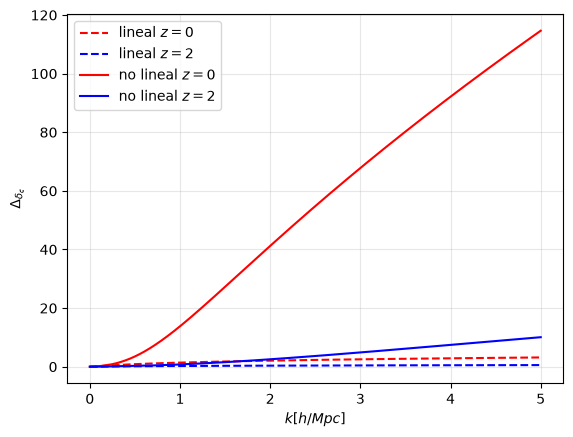

In [98]:
khs = np.logspace(-4, np.log10(5), 10_000) #h/Mpc
zs = [0, 2]

Delta_lin = lambda kh, z: [cosmo.pk_lin(kh_, z) * (kh_ * h)**3 / (2*np.pi**2) for kh_ in kh]
Delta_nl = lambda kh, z: [cosmo_nl.pk(kh_, z) * (kh_ * h)**3 / (2*np.pi**2) for kh_ in kh]

fig, ax = plt.subplots()

colores = {
    '0': 'red',
    '2': 'blue',
}

for z in zs:
    ax.plot(khs, Delta_lin(khs, z), 
            color = colores[f'{z}'], linestyle = '--',
            label = r'$\text{lineal } z = $' + f'{z}')

for z in zs:
    ax.plot(khs, Delta_nl(khs, z), 
            color = colores[f'{z}'],
            label = r'$\text{no lineal } z = $' + f'{z}')

ax.set(xlabel = r'$k [h/Mpc]$', ylabel = r'$\Delta_{\delta_c}$')
ax.grid(alpha = .3), ax.legend()

plt.show()

Como muestra una diferencia muy visible, podemos graficar un cociente entre las dos figuras ($P_{nl} / P_{lin}$) y ver donde podemos encontrar la diferencia del $10\%$.

Para esto hay que tener en cuenta, viendo la comparativa entre las *varianzas*, que $P_{lin} \ll P_{nl}$ para la mayoría de valores de $k_h$, por lo tanto tengo que encontrar el valor de $k_h$ a partir del cual, desde ahí **para adelante** el cociente sea mayor o igual que $1$.

**Código**: luego de ver las figuras y realizar el barrido de $k_{h}$, guardo en un diccionario los valores de número de onda a partir de los cuales la diferencia entre el modelo lineal y no lineal difieren un $10\%$

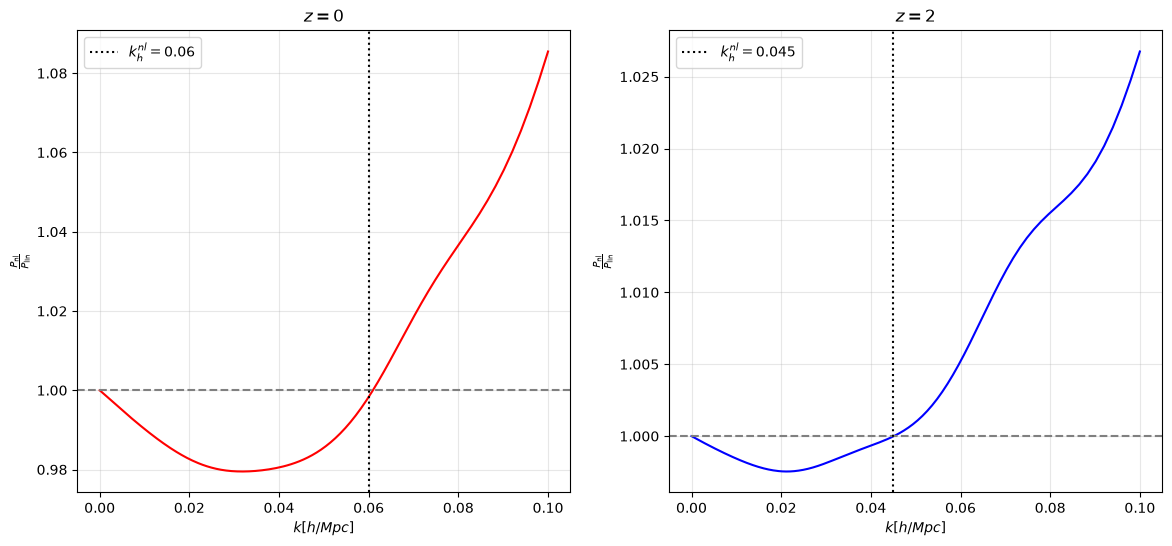

In [123]:
nl_lin = lambda kh, z: [cosmo_nl.pk(kh_, z)/cosmo.pk_lin(kh_, z) for kh_ in kh]
khs_cociente = np.logspace(-10, -1, 1_000)

khnls = {
    '0': .06,
    '2': .045,
}

# Figura luego de autospoilearme los valores que busco
fig, axs = plt.subplots(1, 2, figsize = (14, 6))

for (i, z) in enumerate(zs):
    axs[i].plot(khs_cociente, nl_lin(khs_cociente, z),
                color = colores[f'{z}'])
    axs[i].axhline(1, linestyle = '--', color = 'gray')
    axs[i].axvline(khnls[f'{z}'], linestyle = ':', 
                   color = 'black', 
                   label = r'$k_h^{nl} = $' + f'{khnls[f'{z}']}')

    axs[i].set(ylabel = r'$\frac{P_{\text{nl}}}{P_{\text{lin}}}$',
               xlabel = r'$k [h/Mpc]$', title = r'$z = $' + f'{z}')
    axs[i].grid(alpha = .3), axs[i].legend(loc = 'upper left')

fig.savefig('P3_item_b.png', bbox_inches = 'tight')
plt.show()